# Chapter 7: Risk Measurement I in code

Recomputes the risk measures (delta, gamma, theta, vega, rho) for the book's Figure 7-13 options, checks the position totals in Figure 7-14, tests the delta-plus-gamma estimate, and draws the figures used in the notes.
Notes: [[chapters/07-risk-measurement-i]]

Only the standard library and matplotlib are used. Black-Scholes is used as a tool (the chapter treats it as a black box; the formula is covered later). Units follow the book: delta and gamma in whole numbers (delta 56 means 0.56), theta per calendar day, vega per 1 percentage point of volatility, rho per 1 percentage point of interest rate.

In [1]:
from math import sqrt, exp, log, pi, erf
import matplotlib.pyplot as plt

def N(x):
    """Standard normal cumulative probability."""
    return 0.5 * (1 + erf(x / sqrt(2)))

def pdf(x):
    """Standard normal density (height of the bell curve)."""
    return exp(-x * x / 2) / sqrt(2 * pi)

def bs(S, K, t, r, vol, kind="c"):
    """Black-Scholes value and risk measures for a stock option with no dividend.
    t in years, r and vol as decimals (0.06 = 6%). Returns book units."""
    d1 = (log(S / K) + (r + vol * vol / 2) * t) / (vol * sqrt(t))
    d2 = d1 - vol * sqrt(t)
    call = S * N(d1) - K * exp(-r * t) * N(d2)
    put = call - S + K * exp(-r * t)
    decay = -S * pdf(d1) * vol / (2 * sqrt(t))
    if kind == "c":
        value, delta = call, N(d1)
        theta = decay - r * K * exp(-r * t) * N(d2)
        rho = K * t * exp(-r * t) * N(d2)
    else:
        value, delta = put, N(d1) - 1
        theta = decay + r * K * exp(-r * t) * N(-d2)
        rho = -K * t * exp(-r * t) * N(-d2)
    return dict(value=value,
                delta=delta * 100,
                gamma=pdf(d1) / (S * vol * sqrt(t)) * 100,
                theta=theta / 365,
                vega=S * pdf(d1) * sqrt(t) / 100,
                rho=rho / 100)

# Figure 7-13 inputs
S, vol, r, t = 99.50, 0.25, 0.06, 91 / 365
print("Call 100:", {k: round(x, 3) for k, x in bs(S, 100, t, r, vol, "c").items()})

Call 100: {'value': 5.435, 'delta': 55.65, 'gamma': 3.18, 'theta': -0.035, 'vega': 0.196, 'rho': 0.124}


## Figure 7-13: recompute the table
The book prints theoretical value, delta, gamma, theta, vega and rho for each option. Our own model reproduces them (small differences are rounding, plus two misprints noted in the chapter note).

In [ ]:
book = {  # (kind, strike): (market price, theo value, delta, gamma, theta, vega, rho) as printed
    ("c", 90): (12.30, 11.96, 84, 2.0, -0.029, 0.122, 0.178), ("c", 95): (8.55, 8.33, 71, 2.8, -0.034, 0.170, 0.155),
    ("c", 100): (5.35, 5.44, 56, 3.2, -0.035, 0.196, 0.124), ("c", 105): (3.15, 3.32, 40, 3.1, -0.032, 0.192, 0.091),
    ("c", 110): (1.80, 1.90, 27, 2.6, -0.027, 0.163, 0.062),
    ("p", 90): (1.45, 1.12, -16, 2.0, -0.014, 0.122, -0.043), ("p", 95): (2.63, 2.42, -29, 2.8, -0.019, 0.170, -0.078),
    ("p", 100): (4.35, 4.45, -44, 3.2, -0.019, 0.196, -0.121), ("p", 105): (7.10, 7.26, -60, 3.1, -0.015, 0.192, -0.167),
    ("p", 110): (10.70, 10.77, -73, 2.6, -0.009, 0.163, -0.209),
}
print("kind strike |  value  delta  gamma   theta   vega    rho   (ours; book in brackets)")
for (kind, K), b in book.items():
    g = bs(S, K, t, r, vol, kind)
    print(f"{kind}   {K:>4}   | {g['value']:6.2f} [{b[1]:5.2f}]  {g['delta']:5.1f} [{b[2]:>3}]  {g['gamma']:4.2f} [{b[3]}]  "
          f"{g['theta']:6.3f} [{b[4]:6.3f}]  {g['vega']:5.3f} [{b[5]:5.3f}]  {g['rho']:6.3f} [{b[6]:6.3f}]")

## Figure 7-14: risk measures are additive
Total = sum of (number of contracts, + for bought and - for sold) x (risk measure). We recompute every position from the book's printed table and compare with the totals the book prints. A few printed totals differ: these are flagged `<-- book differs`.

In [ ]:
positions = {
    1: [(-10, "c", 95)],
    2: [(10, "c", 100), (10, "p", 100)],
    3: [(10, "p", 105), (-20, "p", 95)],
    4: [(10, "c", 100), (-10, "c", 90)],
    5: [(-10, "p", 100), (20, "p", 105), (-10, "p", 110)],
}
printed = {  # edge, delta, gamma, theta, vega, rho exactly as printed in Figure 7-14
    1: (2.20, -10, -28, 0.34, -1.70, -1.55),
    2: (-2.10, 120, 64, -0.54, 3.92, 0.30),
    3: (5.80, -10, -25, 0.23, -1.48, 0.11),
    4: (2.30, -280, -12, -0.06, 0.74, -0.54),
    5: (3.50, -30, 4, -0.02, 0.25, -0.04),
}
names = ["edge", "delta", "gamma", "theta", "vega", "rho"]
for n, legs in positions.items():
    tot = [0.0] * 6
    for q, kind, K in legs:
        price, theo, d, g, th, v_, rh = book[(kind, K)]
        tot[0] += q * (theo - price)          # theoretical edge: (theo - price) per option bought, (price - theo) per option sold
        for i, x in enumerate((d, g, th, v_, rh), start=1):
            tot[i] += q * x
    if n == 1:
        tot[1] += 7 * 100                      # position 1 also holds +7 underlying contracts (delta 100 each, nothing else)
    row = []
    for nm, mine, bk in zip(names, tot, printed[n]):
        flag = "" if abs(mine - bk) < 0.011 else "  <-- book differs"
        row.append(f"{nm} {mine:+.2f} (book {bk:+.2f}){flag}")
    print(f"Position {n}:"); [print("   ", x) for x in row]

## Delta and gamma curves
Delta is the slope of the option value; gamma is the slope of delta. Gamma is the same for a call and a put with the same strike and expiry.

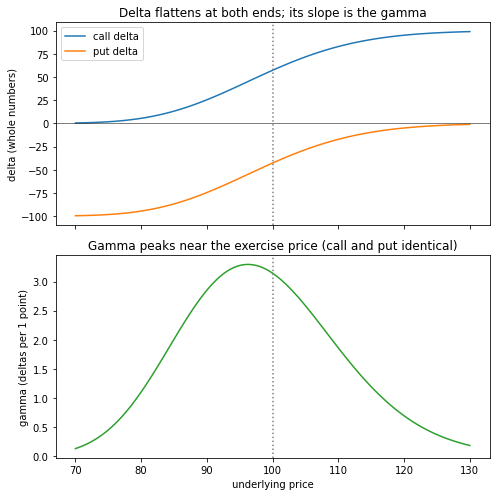

In [2]:
K, t90 = 100, 91 / 365
prices = [70 + 0.5 * i for i in range(0, 121)]   # 70 .. 130
call_delta = [bs(p, K, t90, r, vol, "c")["delta"] for p in prices]
put_delta = [bs(p, K, t90, r, vol, "p")["delta"] for p in prices]
gamma = [bs(p, K, t90, r, vol, "c")["gamma"] for p in prices]

fig, (a, b) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)
a.plot(prices, call_delta, label="call delta"); a.plot(prices, put_delta, label="put delta")
a.axvline(K, color="grey", ls=":"); a.axhline(0, color="black", lw=0.5)
a.set_ylabel("delta (whole numbers)"); a.legend(); a.set_title("Delta flattens at both ends; its slope is the gamma")
b.plot(prices, gamma, color="tab:green"); b.axvline(K, color="grey", ls=":")
b.set_ylabel("gamma (deltas per 1 point)"); b.set_xlabel("underlying price"); b.set_title("Gamma peaks near the exercise price (call and put identical)")
plt.tight_layout(); plt.savefig("../images/ch07-delta-and-gamma.png", dpi=130); plt.show()

## Estimating a new option value: delta only vs delta plus gamma
Use the corrected change $\Delta S = S_2 - S_1$ (the book prints $S_1 - S_2$ in the formulas, which has the wrong sign).

$$C_{\text{new}} \approx C + \Delta S \times \Delta + \tfrac{1}{2}(\Delta S)^2 \times \Gamma$$

First the book's own example, then the same idea checked against the true model value.

In [ ]:
# Book example: S1 = 97.50, C = 3.65, delta 40 (0.40), gamma 2.5 (0.025 per point), S2 = 101.50
C, d, g, dS = 3.65, 0.40, 0.025, 4.0
new_delta = (d + dS * g)
avg_delta = (d + new_delta) / 2
print("new delta:", round(new_delta * 100), " average delta:", round(avg_delta * 100))
print("book estimate:", round(C + dS * avg_delta, 2), " same via delta + gamma terms:", round(C + dS * d + dS * dS * g / 2, 2))
print("with the book's printed sign (S1 - S2 = -4):", round(C + (-dS) * d + dS * dS * g / 2, 2), "<- call falls when stock rises: wrong")

# Check against the model: call 100 from Figure 7-13, stock 99.50 -> 103.50
g0 = bs(S, 100, t90, r, vol, "c")
for S2 in (103.5,):
    dS = S2 - S
    delta_only = g0["value"] + dS * g0["delta"] / 100
    with_gamma = delta_only + 0.5 * dS * dS * g0["gamma"] / 100
    actual = bs(S2, 100, t90, r, vol, "c")["value"]
    print(f"\nS 99.50 -> {S2}: actual {actual:.3f}, delta only {delta_only:.3f}, delta + gamma {with_gamma:.3f}")

In [ ]:
grid = [85 + 0.5 * i for i in range(0, 61)]       # 85 .. 115
actual = [bs(p, K, t90, r, vol, "c")["value"] for p in grid]
delta_only = [g0["value"] + (p - S) * g0["delta"] / 100 for p in grid]
with_gamma = [g0["value"] + (p - S) * g0["delta"] / 100 + 0.5 * (p - S) ** 2 * g0["gamma"] / 100 for p in grid]
plt.figure(figsize=(7, 4.5))
plt.plot(grid, actual, label="model value", lw=2)
plt.plot(grid, delta_only, "--", label="delta only (straight line)")
plt.plot(grid, with_gamma, ":", label="delta + gamma (curved)", lw=2)
plt.axvline(S, color="grey", lw=0.6); plt.ylim(0, 20)
plt.xlabel("underlying price"); plt.ylabel("100 call value"); plt.legend()
plt.title("Gamma bends the delta estimate toward the true curve")
plt.tight_layout(); plt.savefig("../images/ch07-delta-gamma-estimate.png", dpi=130); plt.show()

## Theta: time decay speeds up near expiration

In [ ]:
for days in (91, 21, 3):
    print(f"ATM call (stock = strike = 100, vol 25%, 6%), {days:>2} days left: theta = {bs(100, 100, days/365, r, vol, 'c')['theta']:.3f} per day")

days_left = list(range(90, 0, -1))
values = [bs(100, 100, d / 365, r, vol, "c")["value"] for d in days_left]
thetas = [bs(100, 100, d / 365, r, vol, "c")["theta"] for d in days_left]
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 4))
a.plot(days_left, values); a.invert_xaxis(); a.set_xlabel("days to expiration"); a.set_ylabel("ATM call value"); a.set_title("Value falls faster near the end")
b.plot(days_left, thetas, color="tab:red"); b.invert_xaxis(); b.set_xlabel("days to expiration"); b.set_ylabel("theta per day"); b.set_title("Theta grows more negative")
plt.tight_layout(); plt.savefig("../images/ch07-time-decay.png", dpi=130); plt.show()

### Can theta be positive?
The book's example (a deep in-the-money 60 call with the underlying at 100 and stock-type settlement) is cleanest for an option on a **futures** contract, where the quoted price is also the forward price. We check with the Black (1976) futures-option formula. For a no-dividend **stock** call the forward price is above the stock price, so the time value stays positive; a deep in-the-money European **put** shows negative time value instead.

In [ ]:
def black76(F, K, t, r, vol, kind="c"):
    """Option on a futures contract, stock-type settlement (premium paid up front)."""
    d1 = (log(F / K) + vol * vol / 2 * t) / (vol * sqrt(t)); d2 = d1 - vol * sqrt(t)
    c = exp(-r * t) * (F * N(d1) - K * N(d2)); p = exp(-r * t) * (K * N(-d2) - F * N(-d1))
    return c if kind == "c" else p

print("days left | 60 call on futures at 100 | 60 call on a no-dividend stock at 100 | 140 put on stock at 100   (intrinsic 40 each)")
for days in (182, 120, 60, 30, 1):
    print(f"{days:>8}  | {black76(100, 60, days/365, r, vol):>10.3f} (rises toward 40) | {bs(100, 60, days/365, r, vol, 'c')['value']:>10.3f} (falls toward 40)       | {bs(100, 140, days/365, r, vol, 'p')['value']:>10.3f} (rises toward 40)")

## Vega and position 1 against volatility
Position 1 (sold 10 June 95 calls at 8.55, long 7 underlying): its theoretical profit changes about 1.70 per volatility point. The straight-line (vega) breakeven is what the book calls the implied volatility of the position. The book prints 27.29%, which is a slip: $25 + 2.20/1.70 = 26.29$.

In [ ]:
def position1_profit(v):
    # sold 10 calls at 8.55; the underlying leg has zero theoretical edge and no volatility dependence
    return 10 * (8.55 - bs(S, 95, t, r, v, "c")["value"])

for v in (0.25, 0.26, 0.27):
    print(f"vol {v:.0%}: theoretical profit {position1_profit(v):+.2f}")

lo, hi = 0.25, 0.35                                  # bisection for the exact breakeven
for _ in range(60):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if position1_profit(mid) > 0 else (lo, mid)
print(f"exact breakeven volatility: {lo:.2%}   straight-line estimate: {25 + 2.20/1.70:.2f}%   book prints: 27.29%")

vols = [0.20 + 0.001 * i for i in range(0, 121)]
plt.figure(figsize=(7, 4.5))
plt.plot([v * 100 for v in vols], [position1_profit(v) for v in vols], label="position 1 (model)", lw=2)
plt.plot([25, 27.3], [2.20, 2.20 - 1.70 * 2.3], "--", label="straight line using the vega")
plt.axhline(0, color="black", lw=0.6)
plt.axvline(lo * 100, color="grey", ls=":"); plt.text(lo * 100 + 0.1, 1.5, f"breakeven {lo:.2%}")
plt.xlabel("volatility (%)"); plt.ylabel("theoretical profit"); plt.legend()
plt.title("Vega says the profit falls about 1.70 per volatility point")
plt.tight_layout(); plt.savefig("../images/ch07-position1-vs-volatility.png", dpi=130); plt.show()

## Rho, short stock and the forward price
Interest rate effects on a stock option, and why a short-stock hedge lowers call values (lower forward price).

In [ ]:
# Rho: stock option, 5% -> 6%
a = bs(100, 100, 1, 0.05, 0.25, "c"); b = bs(100, 100, 1, 0.06, 0.25, "c")
print(f"1-year ATM call at 5%: {a['value']:.3f}, at 6%: {b['value']:.3f}, change {b['value'] - a['value']:+.3f} (rho at 5% = {a['rho']:.3f})")
p5 = bs(100, 100, 1, 0.05, 0.25, "p")["value"]; p6 = bs(100, 100, 1, 0.06, 0.25, "p")["value"]
print(f"1-year ATM put: at 5% {p5:.3f}, at 6% {p6:.3f}, change {p6 - p5:+.3f}")
print(f"futures option, stock-type settlement (F = 100, K = 100, 1 year): at 5% {black76(100,100,1,0.05,0.25):.3f}, at 6% {black76(100,100,1,0.06,0.25):.3f}  (both calls and puts fall slightly)")

# Long vs short stock: forward price and C - P (Chapter 2 numbers, simple interest)
Sx, D, tt, K = 67.00, 0.66, 8 / 12, 68.00
for label, rate in (("long stock, r = 6%", 0.06), ("short stock, r = 4%", 0.04)):
    F = Sx * (1 + rate * tt) - D
    print(f"{label}: forward F = {F:.2f}; C - P at K = {K:.0f} is about (F - K)/(1 + 0.06 x 8/12) = {(F - K) / (1 + 0.06 * tt):.3f}")

## Footnote 4: the delta is about 50 at the *forward* price, not at the stock price
Stock 100, one year, interest 10%, so the forward is about 110. We assume a volatility of 20% (the book does not give one).

In [ ]:
for K in (100, 105, 110):
    print(f"strike {K}: call delta {bs(100, K, 1, 0.10, 0.20, 'c')['delta']:.1f}")
print("The 110 call (at the forward) has a delta of 55 here; the 105 call is higher (64). Delta is near 50 around the forward; a lognormal tilt keeps it a little above.")